In [ ]:
# ============================================================
# MODEL COMPARISON with BorderlineSMOTE
# Logistic Regression, Random Forest, XGBoost, SVM
# 5-Fold Stratified Cross-Validation
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (roc_auc_score, recall_score, precision_score,
                              f1_score, make_scorer, confusion_matrix)
from imblearn.over_sampling import BorderlineSMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
import xgboost as xgb
import warnings
warnings.filterwarnings('ignore')

COLOR_PD = '#C0392B'
COLOR_HC = '#2980B9'
COLOR_BG = '#F8F9FA'
GRAY     = '#7F8C8D'

# ── 데이터 로드 ────────────────────────────────────────────
# 경로는 본인 환경에 맞게 수정
df = pd.read_csv(r"C:\Users\asia\Desktop\KKH\SEMI 2 project\PPMI_BSIT12_SCOPA.csv")

# 피처 정의
BSIT_ITEMS  = ['BSIT_CHERRY','BSIT_DILL_PICKLE','BSIT_BANANA','BSIT_CHOCOLATE',
                'BSIT_CINNAMON','BSIT_GASOLINE','BSIT_LEMON','BSIT_ONION',
                'BSIT_PINEAPPLE','BSIT_ROSE','BSIT_SOAP','BSIT_SMOKE']
SCOPA_ITEMS = ['SCOPA_AUT5', 'SCOPA_AUT6', 'SCOPA_AUT7']
FEATURE_COLS = BSIT_ITEMS + SCOPA_ITEMS

X = df[FEATURE_COLS].values
y = df['LABEL_PD'].values   # PD=1, HC=0 (전처리에서 이미 생성됨)

print(f"샘플 수: {len(X)}  |  PD: {y.sum()}  |  HC: {(y==0).sum()}")
print(f"피처 수: {X.shape[1]}")

샘플 수: 944  |  PD: 809  |  HC: 135
피처 수: 15


In [10]:
# ── 모델 정의 ──────────────────────────────────────────────
smote = BorderlineSMOTE(random_state=42, k_neighbors=5)

models = {
    'Logistic\nRegression': ImbPipeline([
        ('smote', smote),
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(max_iter=1000, random_state=42,
                                   class_weight='balanced'))
    ]),
    'Random\nForest': ImbPipeline([
        ('smote', smote),
        ('clf', RandomForestClassifier(n_estimators=200, random_state=42,
                                        class_weight='balanced'))
    ]),
    'XGBoost': ImbPipeline([
        ('smote', smote),
        ('clf', xgb.XGBClassifier(n_estimators=200, random_state=42,
                                   eval_metric='logloss'
                                   ))
    ]),
    'SVM': ImbPipeline([
        ('smote', smote),
        ('scaler', StandardScaler()),
        ('clf', SVC(probability=True, random_state=42,
                    class_weight='balanced'))
    ]),
}

# ── 스코어러 정의 ──────────────────────────────────────────
def specificity_score(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return tn / (tn + fp)

scorers = {
    'AUC':         make_scorer(roc_auc_score, response_method='predict_proba'),
    'Sensitivity': make_scorer(recall_score, pos_label=1),
    'Specificity': make_scorer(specificity_score),
    'F1':          make_scorer(f1_score, pos_label=1),
    'Precision':   make_scorer(precision_score, pos_label=1, zero_division=0),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# ── 교차검증 실행 ──────────────────────────────────────────
results = {}
print("\n[모델 비교 - 5-Fold Stratified CV + BorderlineSMOTE]\n")
print(f"{'Model':<22} {'AUC':>7} {'Sens':>7} {'Spec':>7} {'F1':>7}")
print("─" * 55)

for name, pipeline in models.items():
    cv_results = cross_validate(pipeline, X, y, cv=cv, scoring=scorers,
                                 return_train_score=False, n_jobs=-1)
    results[name] = {metric: cv_results[f'test_{metric}'] for metric in scorers}
    label = name.replace('\n', ' ')
    print(f"{label:<22} "
          f"{results[name]['AUC'].mean():.3f}  "
          f"{results[name]['Sensitivity'].mean():.3f}  "
          f"{results[name]['Specificity'].mean():.3f}  "
          f"{results[name]['F1'].mean():.3f}")


[모델 비교 - 5-Fold Stratified CV + BorderlineSMOTE]

Model                      AUC    Sens    Spec      F1
───────────────────────────────────────────────────────
Logistic Regression    0.826  0.753  0.711  0.835
Random Forest          0.772  0.901  0.407  0.901
XGBoost                0.775  0.888  0.437  0.895
SVM                    0.794  0.829  0.593  0.874


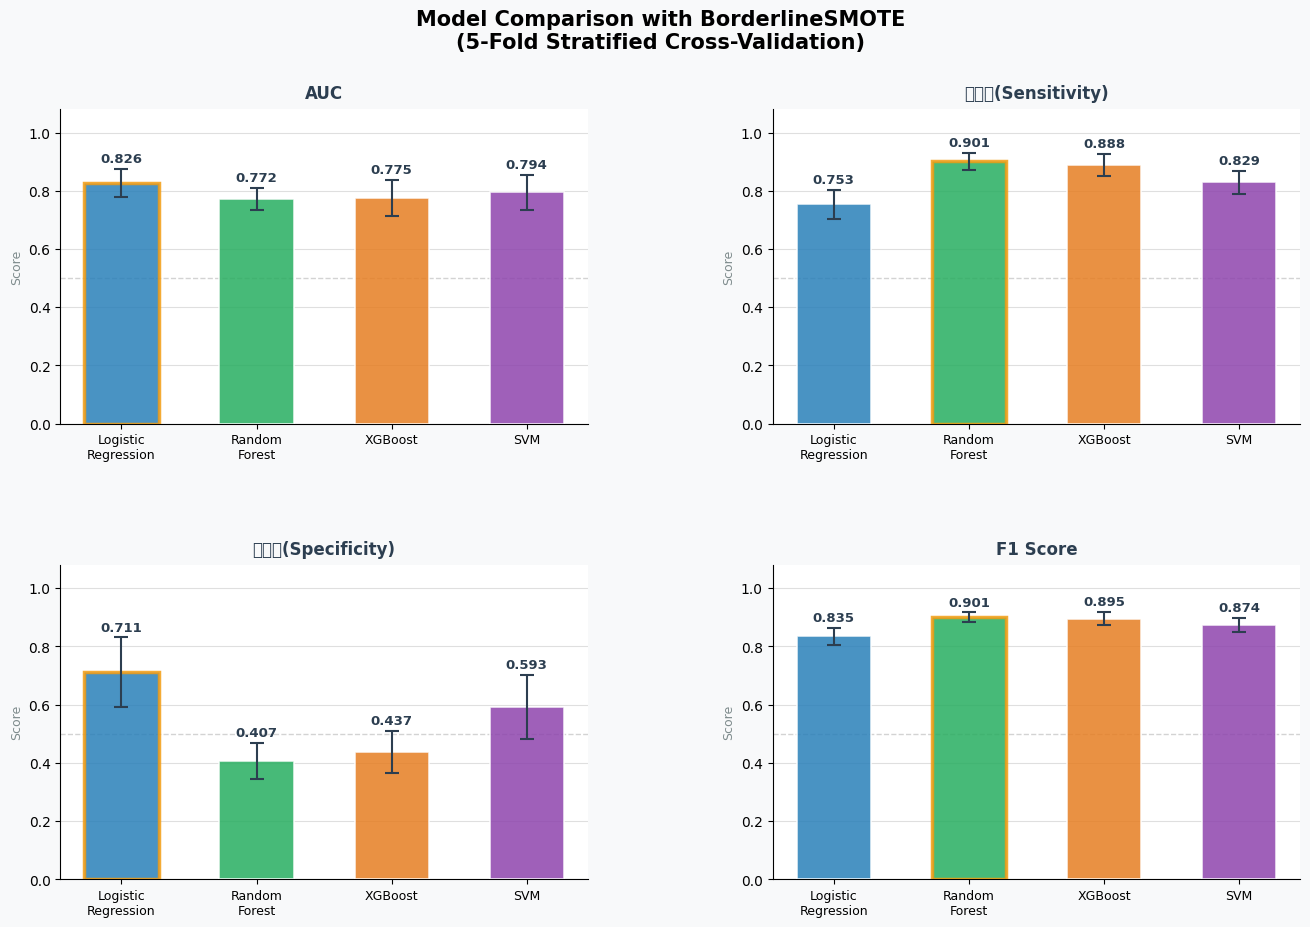

저장 완료: figures/model_comparison_borderline_smote.png


In [11]:
# ── 시각화 ────────────────────────────────────────────────
model_names = list(models.keys())
metrics     = ['AUC', 'Sensitivity', 'Specificity', 'F1']
metric_kr   = {'AUC':'AUC', 'Sensitivity':'민감도(Sensitivity)',
               'Specificity':'특이도(Specificity)', 'F1':'F1 Score'}

fig = plt.figure(figsize=(16, 10), facecolor=COLOR_BG)
fig.suptitle('Model Comparison with BorderlineSMOTE\n(5-Fold Stratified Cross-Validation)',
             fontsize=15, fontweight='bold', y=0.98)

gs      = gridspec.GridSpec(2, 2, figure=fig, hspace=0.45, wspace=0.35)
palette = ['#2980B9', '#27AE60', '#E67E22', '#8E44AD']

for idx, metric in enumerate(metrics):
    ax = fig.add_subplot(gs[idx // 2, idx % 2])
    ax.set_facecolor('white')

    means = [results[m][metric].mean() for m in model_names]
    stds  = [results[m][metric].std()  for m in model_names]
    x_pos = np.arange(len(model_names))

    bars = ax.bar(x_pos, means, color=palette, alpha=0.85,
                  width=0.55, zorder=3, edgecolor='white', linewidth=1.2)
    ax.errorbar(x_pos, means, yerr=stds, fmt='none', color='#2C3E50',
                capsize=5, capthick=1.5, elinewidth=1.5, zorder=4)

    for bar, mean, std in zip(bars, means, stds):
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + std + 0.012,
                f'{mean:.3f}', ha='center', va='bottom',
                fontsize=9.5, fontweight='bold', color='#2C3E50')

    # 최고 모델 금색 테두리
    best_idx = int(np.argmax(means))
    bars[best_idx].set_edgecolor('#F39C12')
    bars[best_idx].set_linewidth(2.5)

    ax.set_title(metric_kr[metric], fontsize=12, fontweight='bold',
                 pad=8, color='#2C3E50')
    ax.set_xticks(x_pos)
    ax.set_xticklabels(model_names, fontsize=9)
    ax.set_ylim(0, 1.08)
    ax.set_ylabel('Score', fontsize=9, color=GRAY)
    ax.axhline(0.5, color='lightgray', linestyle='--', linewidth=1, zorder=1)
    ax.yaxis.grid(True, alpha=0.4, zorder=0)
    ax.set_axisbelow(True)
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)

import os
os.makedirs('figures', exist_ok=True)
plt.savefig('figures/model_comparison_borderline_smote.png',
            dpi=150, bbox_inches='tight', facecolor=COLOR_BG)
plt.show()
print("저장 완료: figures/model_comparison_borderline_smote.png")

In [12]:
# ── 요약 테이블 ────────────────────────────────────────────
print("\n[최종 성능 요약 - Mean ± Std]\n")
print(f"{'Model':<22}", end='')
for m in metrics:
    print(f"  {m:>18}", end='')
print()
print("─" * 100)

for name in model_names:
    label = name.replace('\n', ' ')
    print(f"{label:<22}", end='')
    for m in metrics:
        mean = results[name][m].mean()
        std  = results[name][m].std()
        print(f"  {mean:.3f} ± {std:.3f}   ", end='')
    print()

# AUC + Sensitivity 기준 추천
print("\n★ AUC + Sensitivity 평균 기준 추천 모델:")
scores = {n: results[n]['AUC'].mean()*0.5 + results[n]['Sensitivity'].mean()*0.5
          for n in model_names}
best = max(scores, key=scores.get)
print(f"  → {best.replace(chr(10), ' ')}  (score={scores[best]:.3f})")


[최종 성능 요약 - Mean ± Std]

Model                                  AUC         Sensitivity         Specificity                  F1
────────────────────────────────────────────────────────────────────────────────────────────────────
Logistic Regression     0.826 ± 0.049     0.753 ± 0.051     0.711 ± 0.120     0.835 ± 0.030   
Random Forest           0.772 ± 0.038     0.901 ± 0.028     0.407 ± 0.062     0.901 ± 0.017   
XGBoost                 0.775 ± 0.063     0.888 ± 0.038     0.437 ± 0.072     0.895 ± 0.022   
SVM                     0.794 ± 0.060     0.829 ± 0.039     0.593 ± 0.110     0.874 ± 0.024   

★ AUC + Sensitivity 평균 기준 추천 모델:
  → Random Forest  (score=0.837)


In [ ]:
import joblib
import xgboost as xgb
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import BorderlineSMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

# 1. 최적의 설정으로 최종 모델 파이프라인 생성 
# 성능이 가장 좋았던 XGBoost 기준
final_model = ImbPipeline([
    ('scaler', StandardScaler()),
    ('smote', BorderlineSMOTE(random_state=42)),
    ('classifier', xgb.XGBClassifier(
        random_state=42, 
        use_label_encoder=False, 
        eval_metric='logloss'
    ))
])

# 2. 전체 데이터(X, y)로 최종 학습 
# (이 셀을 실행하기 전에 데이터 로드 셀이 실행되어 있어야 합니다)
try:
    final_model.fit(X, y)
    # 3. 저장
    joblib.dump(final_model, 'olf_con_model.pkl')
    print("✅ 후각/변비 모델(olf_con_model.pkl) 저장 완료!")
except NameError:
    print("❌ 에러: X 또는 y 데이터가 정의되지 않았습니다. 데이터 로드 셀을 먼저 실행하세요.")

✅ 후각/변비 모델(olf_con_model.pkl) 저장 완료!


: 

In [1]:
import joblib
import numpy as np

model = joblib.load('olf_con_model.pkl')

# 완전 정상 케이스: 냄새 12개 다 맡음, 변비 없음
normal = [1,1,1,1,1,1,1,1,1,1,1,1, 0,0,0]
# 완전 이상 케이스: 냄새 12개 다 못 맡음, 변비 최고
abnormal = [0,0,0,0,0,0,0,0,0,0,0,0, 3,3,3]

print("정상 입력 예측 확률:", model.predict_proba([normal]))
print("이상 입력 예측 확률:", model.predict_proba([abnormal]))
print("클래스 레이블:", model.classes_)

정상 입력 예측 확률: [[0.5804328  0.41956726]]
이상 입력 예측 확률: [[2.1582842e-04 9.9978417e-01]]
클래스 레이블: [0 1]
